**BUSINESS UNDERSTANDING**

Penjelasannya apa......

**DATA UNDERSTANDING**

Penjelasannya apa

In [ ]:
# --- 1. Instalasi Library Eksternal ---
!pip install lz4 mtcnn keras-facenet

# --- 2. Standard Library Python ---
import os
import shutil
import pickle
from os import listdir
from base64 import b64decode

# --- 3. Data Processing & Math ---
import numpy as np
from numpy import asarray, expand_dims

# --- 4. Image Processing & Visualization ---
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image as Img

# --- 5. Machine Learning & Deep Learning (TensorFlow/Keras/Sklearn) ---
import tensorflow as tf
from keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- 6. Face Detection & Recognition Specific ---
from mtcnn import MTCNN
from keras_facenet import FaceNet

# --- 7. Google Colab / Jupyter Notebook Utilities ---
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 88.8 MB/s eta 0:00:00
  Created wheel for keras-facenet: filename=keras_facenet-0.3.2-py3-none-any.whl size=10367 sha256=f1b9b8940d3efd4f2b727c4ddeed3dfefc482661fb72cc692b32ea881be20f09
  Stored in directory: /root/.cache/pip/wheels/05/b0/f5/19ac49fedc10b1df3ee56b096edbcfa39d45794fccc6bcdbbf
Successfully built keras-facenet


In [ ]:
!wget "https://drive.google.com/uc?export=download&id=1PZ_6Zsy1Vb0s0JmjEmVd8FS99zoMCiN1"

--2025-12-25 12:32:58--  https://drive.google.com/uc?export=download&id=1PZ_6Zsy1Vb0s0JmjEmVd8FS99zoMCiN1
Resolving drive.google.com (drive.google.com)... 209.85.200.101, 209.85.200.102, 209.85.200.113, ...
Connecting to drive.google.com (drive.google.com)|209.85.200.101|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1PZ_6Zsy1Vb0s0JmjEmVd8FS99zoMCiN1&export=download [following]
--2025-12-25 12:32:58--  https://drive.usercontent.google.com/download?id=1PZ_6Zsy1Vb0s0JmjEmVd8FS99zoMCiN1&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 173.194.206.132, 2607:f8b0:4001:c62::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|173.194.206.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 92397640 (88M) [application/octet-stream]
Saving to: ‘uc?export=download&id=1PZ_6Zsy1Vb0s0JmjEmVd8FS99zoMCiN1’

uc?export=download& 1

In [ ]:
#MyFaceNet = load_model("facenet_keras.h5")
MyFaceNet = FaceNet()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


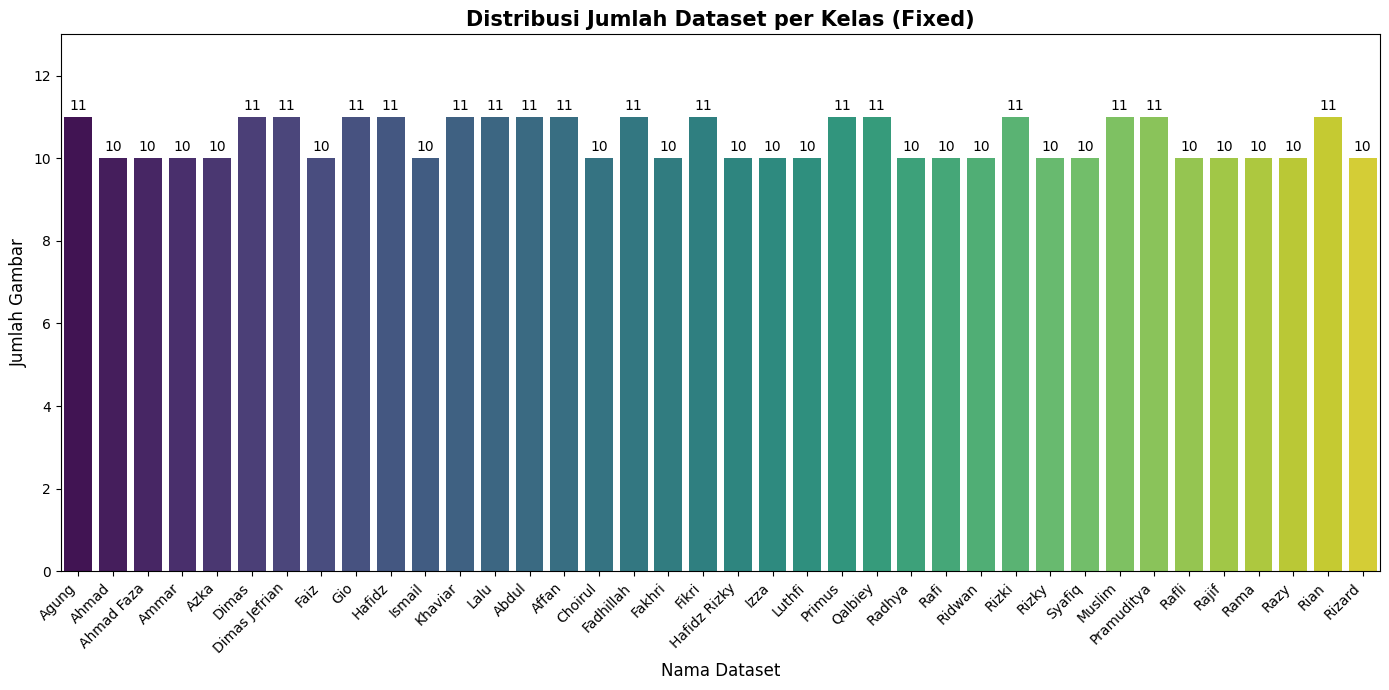

In [ ]:
# GANTI path sesuai struktur folder Drive Anda
dataset_path = '/content/drive/MyDrive/DATASET/WAJAH/'

class_names = []
image_counts = []
display_labels = []

# Dictionary untuk mengecek nama yang sudah terpakai
name_tracker = {}

# Iterasi folder
for folder in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path) and folder != '.ipynb_checkpoints':
        class_names.append(folder)

        # --- LOGIKA PENYINGKATAN BARU (LEBIH AMAN) ---
        words = folder.split()

        # Logika awal
        if words[0] == "M." and len(words) > 1:
            candidate_name = words[1]
        else:
            candidate_name = words[0]

        # CEK DUPLIKASI: Jika nama sudah ada, tambahkan kata berikutnya atau angka
        if candidate_name in display_labels:
            # Jika "Hafidz" sudah ada, gunakan nama lengkap atau tambah inisial
            # Contoh: "Hafidz Sur" (ambil 2 kata)
            if len(words) > 1 and words[0] != "M.":
                 candidate_name = f"{words[0]} {words[1]}"
            elif len(words) > 2 and words[0] == "M.":
                 candidate_name = f"{words[1]} {words[2]}"
            else:
                 candidate_name = f"{candidate_name} (2)"

        display_labels.append(candidate_name)
        # ---------------------------------------------

        # Hitung jumlah file
        count = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
        image_counts.append(count)

# --- Visualisasi ---
plt.figure(figsize=(14, 7)) # Diperlebar

ax = sns.barplot(x=display_labels, y=image_counts, hue=display_labels, palette='viridis', legend=False)

plt.xlabel('Nama Dataset', fontsize=12)
plt.ylabel('Jumlah Gambar', fontsize=12)
plt.title('Distribusi Jumlah Dataset per Kelas (Fixed)', fontsize=15, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.ylim(0, max(image_counts) + 2) # Memberi ruang di atas batang tertinggi

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d') # fmt='%d' memaksa angka bulat

plt.tight_layout()
plt.show()

**DATA PREPARATION**

Penjelasannya apa

In [ ]:
# --- INSTALASI DEPENDENCY ---
!pip install lz4
!pip install mtcnn

import os
import cv2
import shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as Img
from mtcnn import MTCNN

# --- KONFIGURASI ---
# Folder Sumber (Data Mentah di Drive)
folder_sumber = '/content/drive/MyDrive/DATASET/WAJAH/'

# Folder Tujuan (Data Bersih Sementara di Colab)
folder_output_root = '/content/DATA_PREPROCESSED'

# Bersihkan folder tujuan jika sudah ada sebelumnya (biar fresh)
if os.path.exists(folder_output_root):
    shutil.rmtree(folder_output_root)
os.makedirs(folder_output_root)

print("Sedang memuat MTCNN...")
detector = MTCNN()
print("MTCNN Siap! Memulai Preprocessing...")

# Variabel untuk Visualisasi
sample_viz = []

# --- LOOPING PROSES ---
if os.path.exists(folder_sumber):
    # Ambil semua folder kelas
    list_kelas = [f for f in os.listdir(folder_sumber) if os.path.isdir(os.path.join(folder_sumber, f))]
    list_kelas.sort() # Urutkan abjad

    for class_name in list_kelas:
        path_kelas_sumber = os.path.join(folder_sumber, class_name)
        path_kelas_tujuan = os.path.join(folder_output_root, class_name)

        # Buat folder kelas di tujuan
        os.makedirs(path_kelas_tujuan)

        print(f"-> Memproses Kelas: {class_name}")

        ambil_sample = False # Flag untuk ambil 1 foto per kelas

        for filename in os.listdir(path_kelas_sumber):
            file_path = os.path.join(path_kelas_sumber, filename)

            if not filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            try:
                # 1. Baca Gambar
                gbr = cv2.imread(file_path)
                if gbr is None: continue
                gbr_rgb = cv2.cvtColor(gbr, cv2.COLOR_BGR2RGB)

                # 2. Deteksi Wajah
                results = detector.detect_faces(gbr_rgb)
                if not results: continue

                # Ambil wajah dengan confidence tertinggi
                result = results[0]
                if result['confidence'] < 0.95: continue

                # 3. Cropping
                x1, y1, width, height = result['box']
                x1, y1 = abs(x1), abs(y1)
                x2, y2 = x1 + width, y1 + height

                face = gbr_rgb[y1:y2, x1:x2]

                # 4. Resizing (Standar FaceNet 160x160)
                face_pil = Img.fromarray(face)
                face_pil = face_pil.resize((160, 160))

                # 5. Simpan Data Bersih
                save_path = os.path.join(path_kelas_tujuan, filename)
                face_pil.save(save_path)

                # Simpan sample untuk visualisasi (hanya foto pertama yang berhasil)
                if not ambil_sample:
                    sample_viz.append((np.asarray(face_pil), class_name))
                    ambil_sample = True

            except Exception as e:
                pass
                # print(f"Error {filename}: {e}")

    print("\nData Preprocessing Selesai! Data bersih tersimpan di folder '/content/DATA_PREPROCESSED'")

    # --- VISUALISASI HASIL PREPROCESSING ---
    print("\nSAMPLE HASIL CROPPING (1 Foto per Kelas)")
    if len(sample_viz) > 0:
        cols = 5
        rows = (len(sample_viz) // cols) + 1
        plt.figure(figsize=(15, 3 * rows))

        for i in range(len(sample_viz)):
            img, label = sample_viz[i]
            plt.subplot(rows, cols, i + 1)
            plt.imshow(img)
            plt.title(label[:12], fontsize=9) # Potong nama jika kepanjangan
            plt.axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print("Tidak ada wajah yang berhasil dideteksi.")

else:
    print("Folder sumber tidak ditemukan di Google Drive!")

Output hidden; open in https://colab.research.google.com to view.

**MODELLING**

Jelasin.............

In [ ]:
# --- INSTALASI DEPENDENCY ---
!pip install keras-facenet

import os
import numpy as np
from PIL import Image as Img
from numpy import asarray, expand_dims
from keras_facenet import FaceNet
from google.colab import files # Untuk download file

# --- KONFIGURASI ---
# Folder Input (Mengambil dari hasil Preprocessing Bagian 1)
folder_dataset_bersih = '/content/DATA_PREPROCESSED'

print("Sedang memuat model FaceNet...")
embedder = FaceNet()
print("FaceNet Siap! Memulai Modelling (Feature Extraction)...")

face_embeddings = []
face_labels = []

# --- MODELLING ---
if os.path.exists(folder_dataset_bersih):
    list_kelas = sorted(os.listdir(folder_dataset_bersih))

    for class_name in list_kelas:
        path_kelas = os.path.join(folder_dataset_bersih, class_name)

        if not os.path.isdir(path_kelas): continue

        print(f"-> Extracting Features: {class_name}")

        for filename in os.listdir(path_kelas):
            file_path = os.path.join(path_kelas, filename)

            try:
                #Load Gambar Crop
                image = Img.open(file_path)
                image = image.convert('RGB')
                face_array = asarray(image)

                #Proses FaceNet
                face_input = expand_dims(face_array, axis=0)

                #Generate Embedding (Modelling)
                signature = embedder.embeddings(face_input)

                #Simpan ke List
                face_embeddings.append(signature)
                face_labels.append(class_name)

            except Exception as e:
                print(f"Error processing {filename}: {e}")

    # --- PENYIMPANAN MODEL FINAL ---
    print("\n" + "="*40)
    print("MENYIMPAN MODEL (DATABASE WAJAH)")
    print("="*40)

    #Simpan sebagai file NumPy (.npz)
    output_filename = 'data_wajah_facenet.npz'
    np.savez(output_filename, x=face_embeddings, y=face_labels)

    print(f"SUKSES! Total {len(face_labels)} wajah berhasil diproses.")
    print(f"File '{output_filename}' siap didownload untuk Deployment.")

    #Auto Download
    try:
        files.download(output_filename)
    except:
        print("Gagal auto-download. Silakan download manual dari panel Files di kiri.")

else:
    print("Folder data bersih tidak ditemukan! Harap jalankan bagian preparation terlebih dahulu.")

Sedang memuat model FaceNet...
FaceNet Siap! Memulai Modelling (Feature Extraction)...
-> Extracting Features: Agung Susilo Adi Pratama
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
-> Extracting Features: Ahmad Fauzan Albahy
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
-> Extracting Features: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**EVALUATION**

Jelasin................

Sedang memuat Database Wajah (.npz)...
Database dimuat: 392 wajah terdaftar.
Sedang memuat MTCNN & FaceNet...

Memulai Evaluasi... (Mohon tunggu, proses tergantung jumlah data)
-> Menguji Kelas: Azka Acuzio Rainea R
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
-> Menguji Kelas: M. Hafidz Rizky Rahmawan
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━

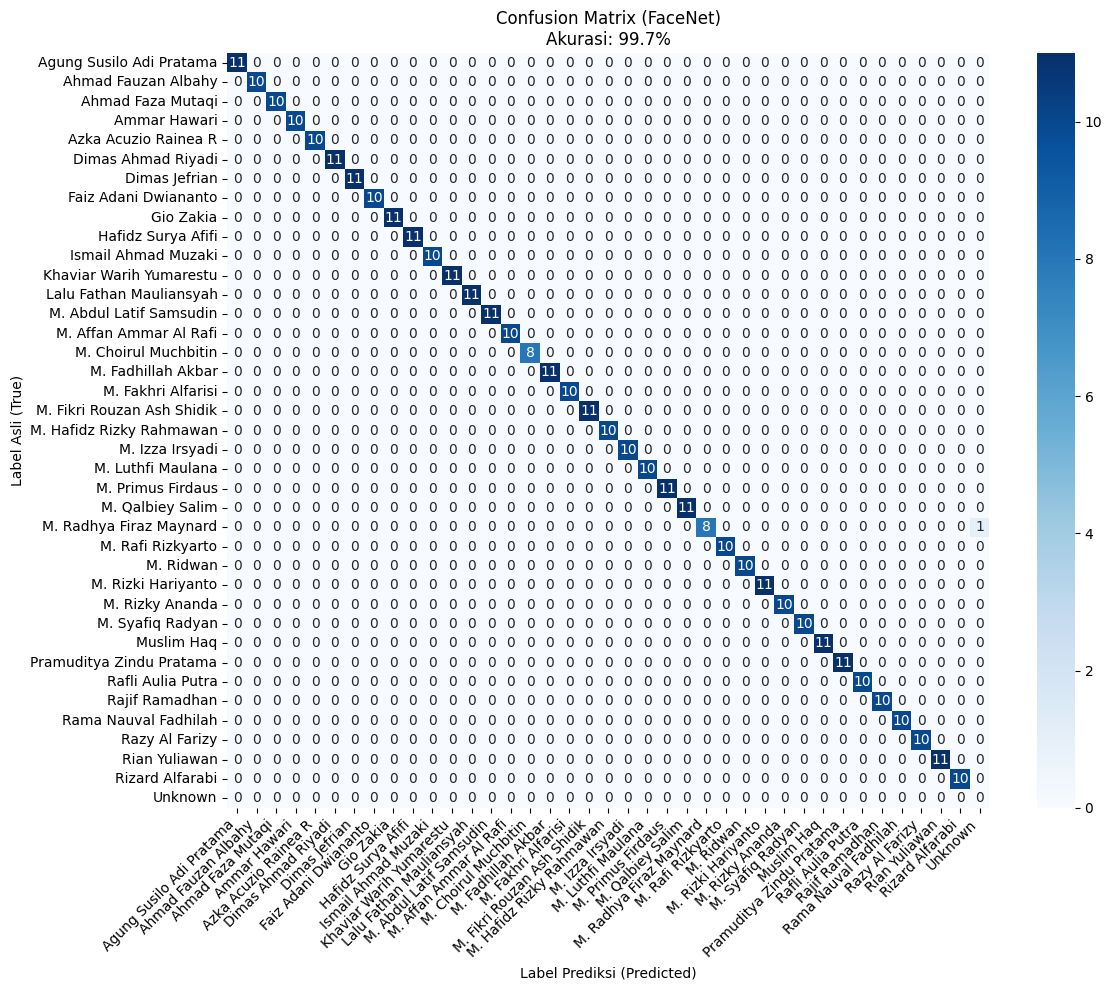

In [ ]:
folder_uji = '/content/drive/MyDrive/DATASET/WAJAH/'

# Load Database Pengetahuan (Model yang sudah dibuat di tahap Modelling)
print("Sedang memuat Database Wajah (.npz)...")
try:
    data = np.load('data_wajah_facenet.npz')
    X_db = data['x'] # Embeddings database
    Y_db = data['y'] # Label database
    print(f"Database dimuat: {len(Y_db)} wajah terdaftar.")
except:
    print("Error: File 'data_wajah_facenet.npz' tidak ditemukan! Jalankan tahap Modelling dulu.")
    exit()

# Load Model AI
print("Sedang memuat MTCNN & FaceNet...")
detector = MTCNN()
embedder = FaceNet()

# Setting Threshold (Batas Kemiripan)
# Jika jarak < 0.75 dianggap Kenal. Di atas itu Unknown (atau salah).
THRESHOLD = 0.75

# Variabel Hasil
y_true = [] # Label Sebenarnya (Nama Folder)
y_pred = [] # Label Prediksi (Tebakan AI)

# --- 3. LOOPING PENGUJIAN ---
print("\nMemulai Evaluasi... (Mohon tunggu, proses tergantung jumlah data)")

if os.path.exists(folder_uji):
    for class_name in os.listdir(folder_uji):
        path_kelas = os.path.join(folder_uji, class_name)

        # Pastikan ini folder
        if not os.path.isdir(path_kelas): continue

        print(f"-> Menguji Kelas: {class_name}")

        for filename in os.listdir(path_kelas):
            file_path = os.path.join(path_kelas, filename)

            if not filename.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            try:
                # A. Preprocessing (Sama seperti tahap sebelumnya)
                gbr = cv2.imread(file_path)
                if gbr is None: continue
                gbr_rgb = cv2.cvtColor(gbr, cv2.COLOR_BGR2RGB)

                # Deteksi Wajah
                results = detector.detect_faces(gbr_rgb)
                if not results: continue # Skip jika wajah tidak ketemu

                # Ambil confidence tertinggi
                result = results[0]
                if result['confidence'] < 0.90: continue

                x1, y1, width, height = result['box']
                x1, y1 = abs(x1), abs(y1)
                x2, y2 = x1 + width, y1 + height

                face = gbr_rgb[y1:y2, x1:x2]
                face_pil = Img.fromarray(face).resize((160, 160))
                face_array = asarray(face_pil)

                # B. Feature Extraction (FaceNet)
                face_input = expand_dims(face_array, axis=0)
                new_embedding = embedder.embeddings(face_input)

                # C. Recognition (Hitung Jarak)
                distances = []
                for db_emb in X_db:
                    dist = np.linalg.norm(new_embedding - db_emb)
                    distances.append(dist)

                # Cari yang paling mirip
                min_dist = min(distances)
                index_min = distances.index(min_dist)

                # Tebakan Sistem
                if min_dist < THRESHOLD:
                    predicted_name = Y_db[index_min]
                else:
                    predicted_name = "Unknown"

                # Simpan Data untuk Evaluasi
                y_true.append(class_name)      # Kunci Jawaban
                y_pred.append(predicted_name)  # Jawaban Siswa (AI)

            except Exception as e:
                pass

    print("\nEvaluasi Selesai!")

    # --- 4. MENAMPILKAN HASIL METRIKS ---
    print("\n" + "="*50)
    print("LAPORAN EVALUASI MODEL (CRISP-DM)")
    print("="*50)

    # Hitung Metriks
    acc = accuracy_score(y_true, y_pred)
    print(f"Akurasi Total: {acc * 100:.2f}%")
    print("\n--- Classification Report (Precision, Recall, F1-Score) ---")

    # zero_division=0 agar tidak error jika ada kelas yang tidak terdeteksi sama sekali
    print(classification_report(y_true, y_pred, zero_division=0))

    # --- 5. VISUALISASI CONFUSION MATRIX ---
    # Buat Matrix
    cm = confusion_matrix(y_true, y_pred)

    # Ambil label unik yang muncul di hasil evaluasi
    labels = sorted(list(set(y_true + y_pred)))

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(f'Confusion Matrix (FaceNet)\nAkurasi: {acc*100:.1f}%')
    plt.ylabel('Label Asli (True)')
    plt.xlabel('Label Prediksi (Predicted)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

else:
    print("Folder Data Uji tidak ditemukan.")

Sedang memuat database dan model...
Database berhasil dimuat.

Silakan klik tombol 'Capture' yang muncul di bawah...


<IPython.core.display.Javascript object>

Foto berhasil diambil!
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step

--- HASIL ANALISIS ---
Nilai Kemiripan: 0.6380
Identitas: Khaviar Warih Yumarestu


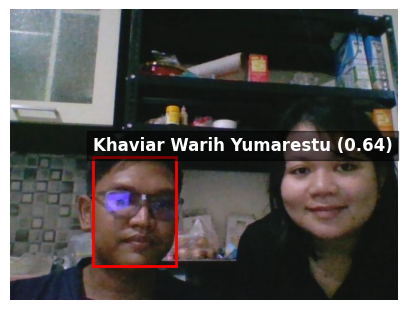

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image as Img
from numpy import asarray, expand_dims
from mtcnn import MTCNN
from keras_facenet import FaceNet

# --- 1. FUNGSI UNTUK AKSES WEBCAM DI COLAB ---
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

# --- 2. LOAD MODEL DAN DATABASE ---
print("Sedang memuat database dan model...")

# Load Database Wajah yang sudah ditraining
try:
    data = np.load('data_wajah_facenet.npz')
    X_db = data['x'] # Data embedding (angka)
    Y_db = data['y'] # Label nama
    print("Database berhasil dimuat.")
except:
    print("Error: File 'data_wajah_facenet.npz' tidak ditemukan! Jalankan training dulu.")

# Load Model
detector = MTCNN()
MyFaceNet = FaceNet()

# --- 3. AMBIL FOTO & DETEKSI ---
try:
    print("\nSilakan klik tombol 'Capture' yang muncul di bawah...")
    filename = take_photo()
    print('Foto berhasil diambil!')

    # Baca gambar
    gbr = cv2.imread(filename)
    gbr_rgb = cv2.cvtColor(gbr, cv2.COLOR_BGR2RGB)

    # Deteksi Wajah
    results = detector.detect_faces(gbr_rgb)

    if len(results) > 0:
        # Ambil wajah terbesar
        x1, y1, width, height = results[0]['box']
        x1, y1 = abs(x1), abs(y1)
        x2, y2 = x1 + width, y1 + height

        # Crop & Resize
        face = gbr_rgb[y1:y2, x1:x2]
        face_pil = Img.fromarray(face)
        face_pil = face_pil.resize((160, 160))
        face_array = asarray(face_pil)

        # Embedding (Ubah jadi angka)
        face_input = expand_dims(face_array, axis=0)
        signature_target = MyFaceNet.embeddings(face_input)

        # --- 4. PENGENALAN (MENGHITUNG JARAK) ---
        # Bandingkan wajah di kamera dengan SEMUA wajah di database
        distone = []
        for db_emb in X_db:
            # Euclidean Distance
            dist = np.linalg.norm(signature_target - db_emb)
            distone.append(dist)

        # Cari jarak terdekat (paling mirip)
        min_dist = min(distone)
        index_min = distone.index(min_dist)

        # Ambang batas (Threshold)
        # 0.7 - 0.8 biasanya angka yang pas.
        # Jika < 0.7 berarti SANGAT MIRIP. Jika > 0.8 mungkin orang lain.
        threshold = 0.75

        if min_dist < threshold:
            identity = Y_db[index_min]
            status = "COCOK / MATCH"
            color = (0, 255, 0) # Hijau
        else:
            identity = "Tidak Dikenal (Unknown)"
            status = "TIDAK COCOK"
            color = (255, 0, 0) # Merah

        # --- 5. TAMPILKAN HASIL ---
        print(f"\n--- HASIL ANALISIS ---")
        print(f"Nilai Kemiripan: {min_dist:.4f}")
        print(f"Identitas: {identity}")

        plt.figure(figsize=(5,5))
        plt.imshow(gbr_rgb)

        # Gambar kotak di wajah
        ax = plt.gca()
        rect = plt.Rectangle((x1, y1), width, height, fill=False, color='red', linewidth=2)
        ax.add_patch(rect)

        # Tulis Nama
        plt.text(x1, y1-10, f"{identity} ({min_dist:.2f})", color='white', fontsize=12, fontweight='bold', bbox=dict(facecolor='black', alpha=0.5))
        plt.axis('off')
        plt.show()

    else:
        print("Wajah tidak terdeteksi di kamera!")

except Exception as e:
    print(str(e))